In [5]:
import numpy as np
import math
import numpy as np
import matplotlib.pyplot as plt
from UQpy.distributions import Uniform, JointIndependent
from UQpy.surrogates import *

In [6]:
# function to be approximated
def ishigami(xx):
    """Ishigami function"""
    a = 50
    b = 0.1
    term1 = np.sin(xx[0])
    term2 = a * np.sin(xx[1])**2
    term3 = b * xx[2]**4 * np.sin(xx[0])
    return term1 + term2 + term3

In [7]:
# input distributions
dist1 = Uniform(loc=-np.pi, scale=2*np.pi)
dist2 = Uniform(loc=-np.pi, scale=2*np.pi)
dist3 = Uniform(loc=-np.pi, scale=2*np.pi)
marg = [dist1, dist2, dist3]
joint = JointIndependent(marginals=marg)

In [8]:
# maximum polynomial degree
P = 6

# construct total-degree polynomial basis
polynomial_basis = TotalDegreeBasis(joint, P)

# check the size of the basis
print('Size of PCE basis:', polynomial_basis.polynomials_number)

Size of PCE basis: 84


In [9]:
# create training data
sample_size = int(polynomial_basis.polynomials_number*5)
print('Size of experimental design:', sample_size)

# realizations of random inputs
xx_train = joint.rvs(sample_size)
# corresponding model outputs
yy_train = np.array([ishigami(x) for x in xx_train])

Size of experimental design: 420


In [10]:
# fit model
least_squares = LeastSquareRegression()
pce = PolynomialChaosExpansion(polynomial_basis=polynomial_basis, regression_method=least_squares)

pce.fit(xx_train, yy_train)

In [11]:
mean_est = pce.get_moments()[0]
var_est = pce.get_moments()[1]
print('PCE mean estimate:', mean_est)
print('PCE variance estimate:', var_est)

PCE mean estimate: 25.117750794443293
PCE variance estimate: 319.52467895328977


In [12]:
from UQpy.sensitivity import *
pce_sensitivity = PceSensitivity(pce)
pce_sensitivity.run()
sobol_first = pce_sensitivity.first_order_indices
sobol_total = pce_sensitivity.total_order_indices
print('First-order Sobol indices:')
print(sobol_first)
print('Total-order Sobol indices:')
print(sobol_total)

First-order Sobol indices:
[[1.47963416e-02]
 [9.68685381e-01]
 [3.98608203e-04]]
Total-order Sobol indices:
[[0.03042729]
 [0.97410221]
 [0.01532647]]


In [13]:
# validation data sets
np.random.seed(999)  # fix random seed for reproducibility
n_samples_val = 10000
xx_val = joint.rvs(n_samples_val)
yy_val = np.array([ishigami(x) for x in xx_val])

mae = []  # to hold MAE for increasing polynomial degree
for degree in range(16):
    # define PCE
    polynomial_basis = TotalDegreeBasis(joint, degree)
    least_squares = LeastSquareRegression()
    pce_metamodel = PolynomialChaosExpansion(polynomial_basis=polynomial_basis, regression_method=least_squares)

    # create training data
    np.random.seed(1)  # fix random seed for reproducibility
    sample_size = int(pce_metamodel.polynomials_number * 5)
    xx_train = joint.rvs(sample_size)
    yy_train = np.array([ishigami(x) for x in xx_train])

    # fit PCE coefficients
    pce_metamodel.fit(xx_train, yy_train)

    # compute mean absolute validation error
    yy_val_pce = pce_metamodel.predict(xx_val).flatten()
    errors = np.abs(yy_val.flatten() - yy_val_pce)
    mae.append(np.linalg.norm(errors, 1) / n_samples_val)

    print('Polynomial degree:', degree)
    print('Mean absolute error:', mae[-1])
    print(' ')

Polynomial degree: 0
Mean absolute error: 16.14768013754897
 
Polynomial degree: 1
Mean absolute error: 16.57273548051487
 
Polynomial degree: 2
Mean absolute error: 15.406932916914139
 
Polynomial degree: 3
Mean absolute error: 16.298889418491594
 
Polynomial degree: 4
Mean absolute error: 9.699872604101579
 
Polynomial degree: 5
Mean absolute error: 9.94169752253281
 
Polynomial degree: 6
Mean absolute error: 2.4005440063401413
 
Polynomial degree: 7
Mean absolute error: 2.304695739289579
 
Polynomial degree: 8
Mean absolute error: 0.34480393305820645
 
Polynomial degree: 9
Mean absolute error: 0.3141934212116872
 
Polynomial degree: 10
Mean absolute error: 0.028319590692067072
 
Polynomial degree: 11
Mean absolute error: 0.027732161301458377
 
Polynomial degree: 12
Mean absolute error: 0.0016707372045729838
 
Polynomial degree: 13
Mean absolute error: 0.0018570024022523327
 
Polynomial degree: 14
Mean absolute error: 7.961027264035863e-05
 
Polynomial degree: 15
Mean absolute error:

In [17]:
 # vytvoření funkce PCE
def build_pce(degree, sample_size):

    basis = TotalDegreeBasis(joint, degree)

    pce = PolynomialChaosExpansion( polynomial_basis=basis, regression_method=LeastSquareRegression() )

    xx_train = joint.rvs(sample_size)
    yy_train = np.array([ishigami(x) for x in xx_train])

    pce.fit(xx_train, yy_train)

    return pce

P=1, N=10, MAE=16.186514609548457
P=1, N=100, MAE=16.150928940095074
P=1, N=420, MAE=15.898043528624816
P=1, N=1000, MAE=15.897669570530631
P=1, N=4000, MAE=15.852066631102515
P=1, N=5000, MAE=15.854985139459965
P=1, N=8000, MAE=15.854089538590452
P=1, N=10000, MAE=15.850792229260572
P=4, N=10, MAE=22.594772705293273
P=4, N=100, MAE=10.41071719039884
P=4, N=420, MAE=9.311503149026708
P=4, N=1000, MAE=8.949187429011392
P=4, N=4000, MAE=8.90646166790905
P=4, N=5000, MAE=8.897460133266758
P=4, N=8000, MAE=8.878731522540807
P=4, N=10000, MAE=8.86760900527541
P=6, N=10, MAE=22.658673422584695
P=6, N=100, MAE=9.580909135927854
P=6, N=420, MAE=2.327299012595435
P=6, N=1000, MAE=2.21587310240485
P=6, N=4000, MAE=2.172005904766683
P=6, N=5000, MAE=2.171326678707217
P=6, N=8000, MAE=2.1555700633425077
P=6, N=10000, MAE=2.1585579735719502
P=10, N=10, MAE=24.33254073386556
P=10, N=100, MAE=15.649751970563276
P=10, N=420, MAE=0.11837556467227166
P=10, N=1000, MAE=0.030718154927869522
P=10, N=4000, 

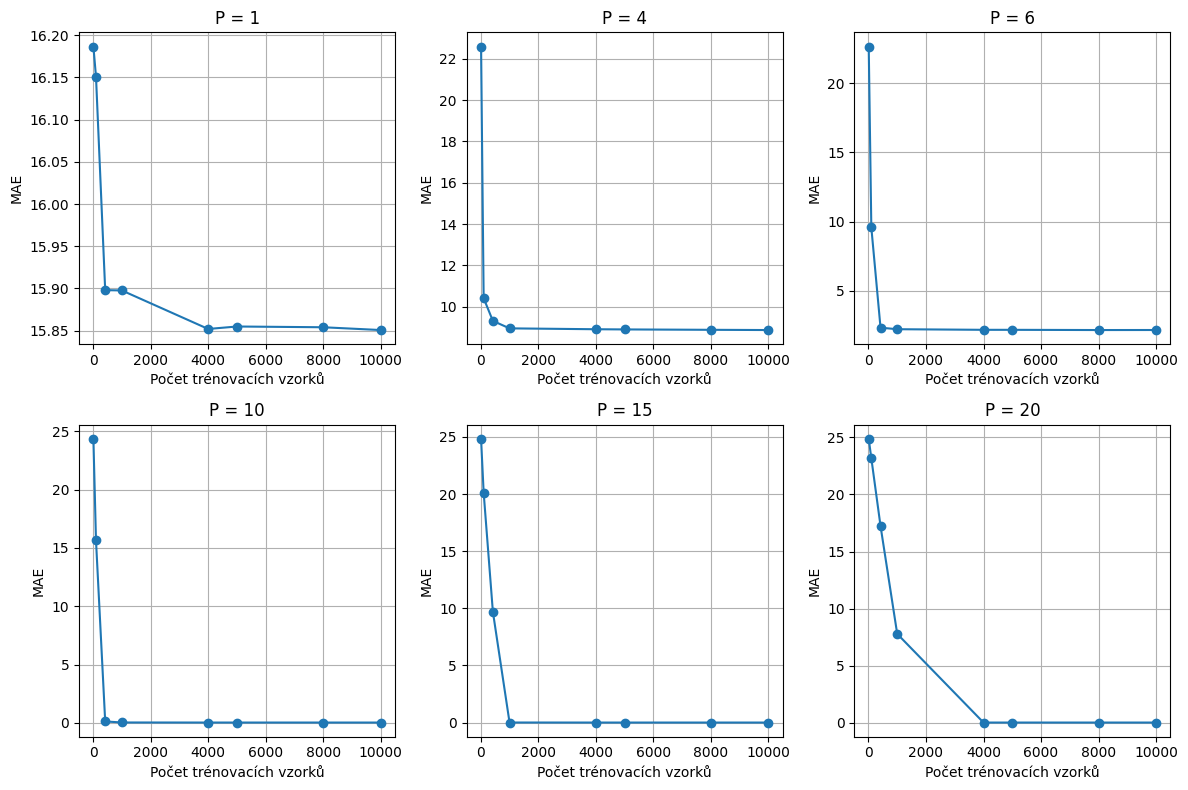

In [24]:
degrees = [1,4,6,10,15,20] 

sample_sizes = [10, 100, 420, 1000,4000, 5000, 8000, 10000]

all_mae = {}

fig, ax = plt.subplots(2, 3, figsize=(12, 8))
ax = ax.flatten()

for i, degree in enumerate(degrees):
    
    mae = []
    
    for sample_size in sample_sizes:

        pce = build_pce(degree, sample_size)
        
        yy_val_pce = pce.predict(xx_val).flatten()
        
        error = np.mean(np.abs(yy_val - yy_val_pce))
        
        mae.append(error)
        print(f"P={degree}, N={sample_size}, MAE={error}")
        
    all_mae[degree] = mae
        
    
         # print('Sample size:',sample_size)
         # print('Mean absolute error:', error)
        

    ax[i].plot(sample_sizes, mae, 'o-')
    ax[i].set_title(f'P = {degree}')
    ax[i].set_xlabel('Počet trénovacích vzorků')
    ax[i].set_ylabel('MAE')
    ax[i].grid(True)

plt.tight_layout()
plt.show()

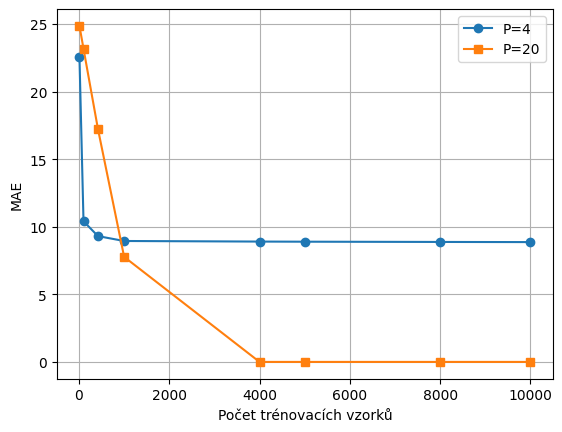

In [25]:
plt.plot(sample_sizes, all_mae[4], 'o-', label='P=4')
plt.plot(sample_sizes, all_mae[20], 's-', label='P=20')

plt.xlabel('Počet trénovacích vzorků')
plt.ylabel('MAE')
plt.legend()
plt.grid(True)

plt.show()

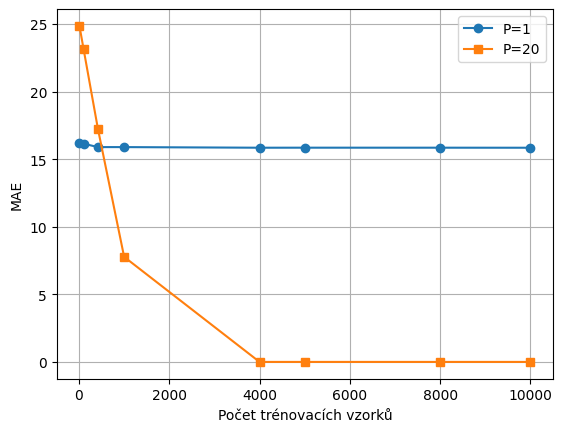

In [26]:
plt.plot(sample_sizes, all_mae[1], 'o-', label='P=1')
plt.plot(sample_sizes, all_mae[20], 's-', label='P=20')

plt.xlabel('Počet trénovacích vzorků')
plt.ylabel('MAE')
plt.legend()
plt.grid(True)

plt.show()

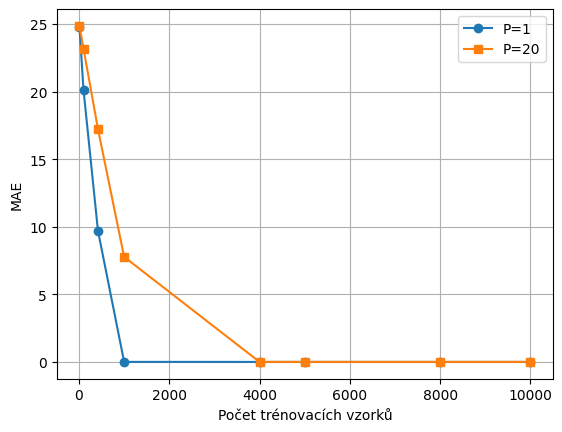

In [27]:
plt.plot(sample_sizes, all_mae[15], 'o-', label='P=1')
plt.plot(sample_sizes, all_mae[20], 's-', label='P=20')

plt.xlabel('Počet trénovacích vzorků')
plt.ylabel('MAE')
plt.legend()
plt.grid(True)

plt.show()

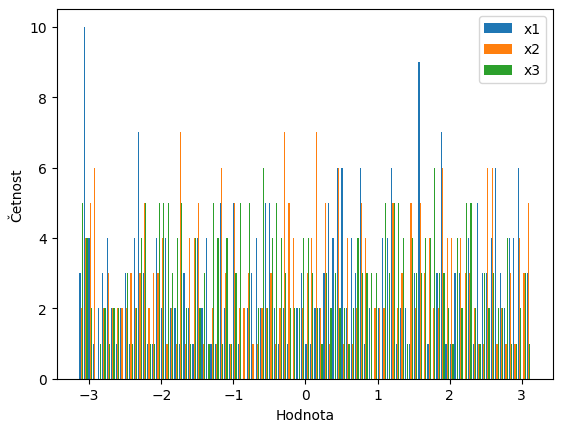

In [116]:
plt.hist([xx_train[:,0],xx_train[:,1],xx_train[:,2]],bins=100,label=['x1', 'x2', 'x3'])

plt.xlabel('Hodnota')
plt.ylabel('Četnost')
plt.legend()
plt.show()

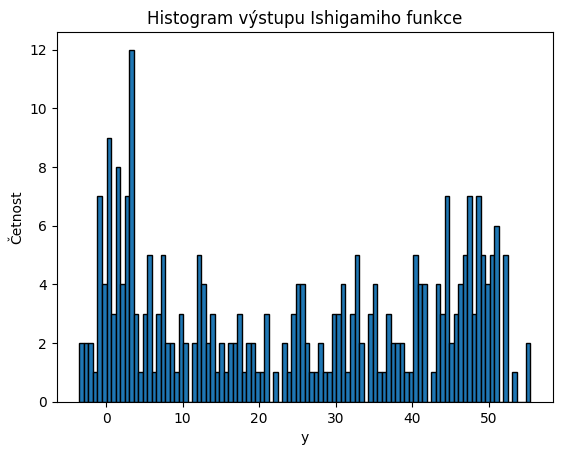

In [117]:
plt.hist(yy_train, bins=100, edgecolor='black')
plt.xlabel('y')
plt.ylabel('Četnost')
plt.title('Histogram výstupu Ishigamiho funkce')
plt.show()

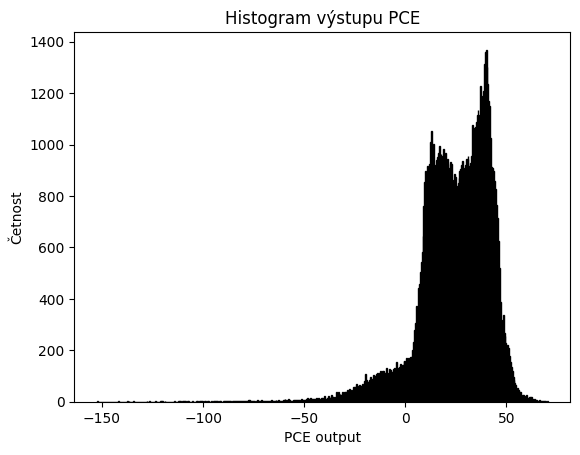

In [118]:
import matplotlib.pyplot as plt

plt.hist(yy_val_pce, bins=500, edgecolor='black')
plt.xlabel('PCE output')
plt.ylabel('Četnost')
plt.title('Histogram výstupu PCE')
plt.show()

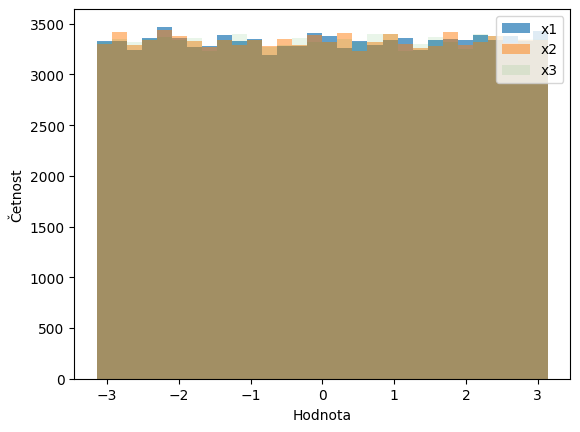

In [119]:
plt.hist(xx_val[:,0], bins=30, alpha=0.7, label='x1')
plt.hist(xx_val[:,1], bins=30, alpha=0.5, label='x2')
plt.hist(xx_val[:,2], bins=30, alpha=0.1, label='x3')

plt.xlabel('Hodnota')
plt.ylabel('Četnost')
plt.legend()
plt.show()

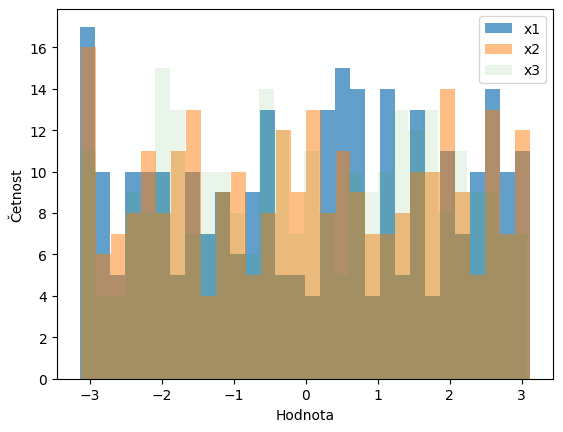

In [120]:
plt.hist(xx_train[:,0], bins=30, alpha=0.7, label='x1')
plt.hist(xx_train[:,1], bins=30, alpha=0.5, label='x2')
plt.hist(xx_train[:,2], bins=30, alpha=0.1, label='x3')

plt.xlabel('Hodnota')
plt.ylabel('Četnost')
plt.legend()
plt.show()

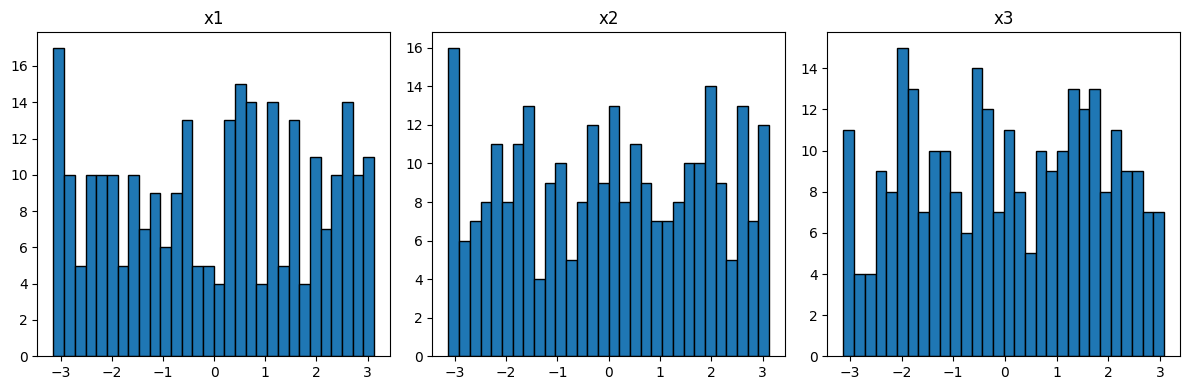

In [121]:
fig, ax = plt.subplots(1, 3, figsize=(12,4))

ax[0].hist(xx_train[:,0], bins=30, edgecolor='black')
ax[0].set_title('x1')

ax[1].hist(xx_train[:,1], bins=30, edgecolor='black')
ax[1].set_title('x2')

ax[2].hist(xx_train[:,2], bins=30, edgecolor='black')
ax[2].set_title('x3')

plt.tight_layout()
plt.show()

In [122]:
print(xx_train[0])
print(yy_train[0])

[-0.52136612  2.38759966 -2.99761264]
18.911206668429443


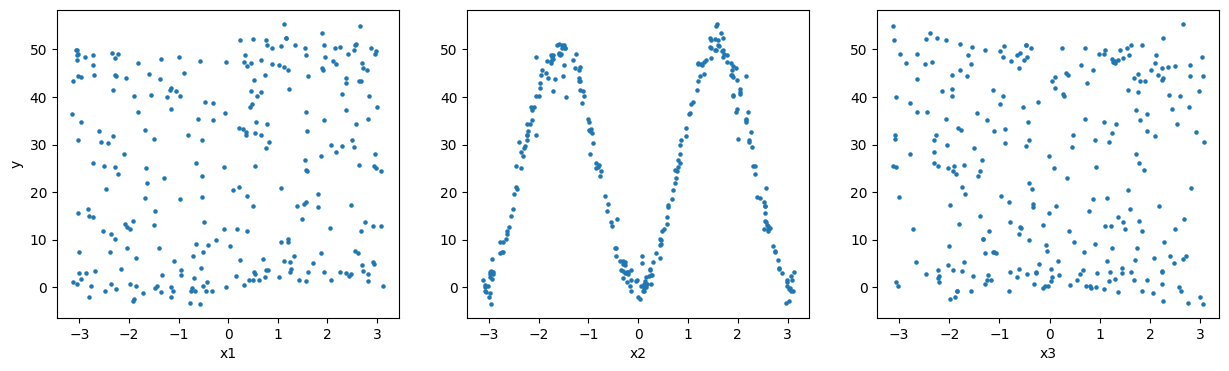

In [123]:
fig, ax = plt.subplots(1,3, figsize=(15,4))

ax[0].scatter(xx_train[:,0], yy_train, s=5)
ax[0].set_xlabel('x1')
ax[0].set_ylabel('y')

ax[1].scatter(xx_train[:,1], yy_train, s=5)
ax[1].set_xlabel('x2')

ax[2].scatter(xx_train[:,2], yy_train, s=5)
ax[2].set_xlabel('x3')


plt.show()

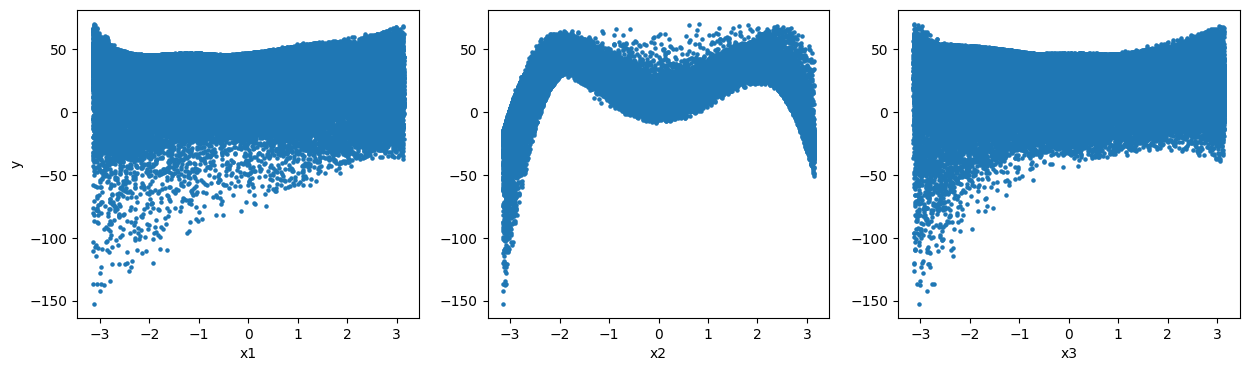

In [124]:
fig, ax = plt.subplots(1,3, figsize=(15,4))

ax[0].scatter(xx_val[:,0], yy_val_pce, s=5)
ax[0].set_xlabel('x1')
ax[0].set_ylabel('y')

ax[1].scatter(xx_val[:,1], yy_val_pce, s=5)
ax[1].set_xlabel('x2')

ax[2].scatter(xx_val[:,2], yy_val_pce, s=5)
ax[2].set_xlabel('x3')


plt.show()

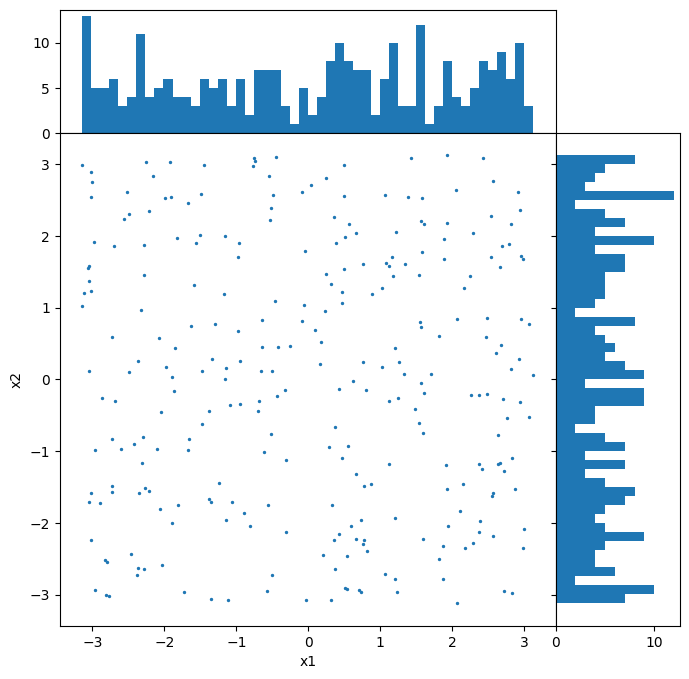

In [125]:
fig = plt.figure(figsize=(8,8))

gs = fig.add_gridspec(
    2, 2,
    width_ratios=(4,1),
    height_ratios=(1,4),    hspace=0.0,
    wspace=0.0)

ax_histx = fig.add_subplot(gs[0,0])
ax_scatter = fig.add_subplot(gs[1,0])
ax_histy = fig.add_subplot(gs[1,1])

x = xx_train[:,0]
y = xx_train[:,1]

ax_scatter.scatter(x, y, s=2)

ax_histx.hist(x, bins=50)
ax_histy.hist(y, bins=50, orientation='horizontal')

ax_histx.tick_params(axis='x', labelbottom=False)
ax_histy.tick_params(axis='y', labelleft=False)

ax_scatter.set_xlabel('x1')
ax_scatter.set_ylabel('x2')

plt.show()

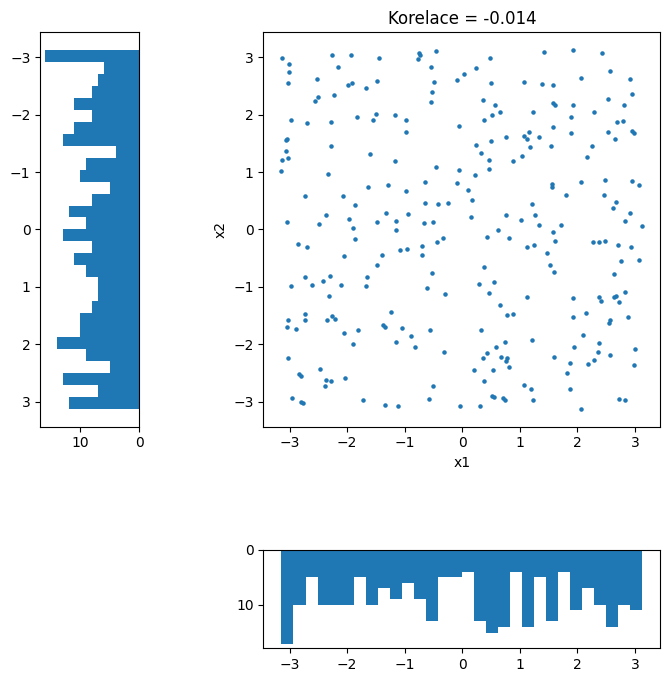

In [126]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(8,8))

gs = fig.add_gridspec( 2, 2, width_ratios=(1,4), height_ratios=(4,1), hspace=0.5, wspace=0.5)

# osy
ax_histy = fig.add_subplot(gs[0,0])
ax_scatter = fig.add_subplot(gs[0,1])
ax_histx = fig.add_subplot(gs[1,1])

# data
x = xx_train[:,0]   # x1
y = xx_train[:,1]   # x2

# hlavní graf
ax_scatter.scatter(x, y, s=5)

# histogram x1 dole
ax_histx.hist(x, bins=30)
ax_histy.invert_yaxis()
ax_histx.invert_yaxis()

# histogram x2 vlevo
ax_histy.hist(y, bins=30, orientation='horizontal')
ax_histy.invert_xaxis()

# popisky
ax_scatter.set_xlabel('x1')
ax_scatter.set_ylabel('x2')

# spočítaní korelace
corr = np.corrcoef(x, y)[0,1]
ax_scatter.set_title(f'Korelace = {corr:.3f}')

plt.show()


In [127]:
corr = np.corrcoef(x, y)[0, 1]

print("Korelace =", corr)

Korelace = -0.013724578292830183


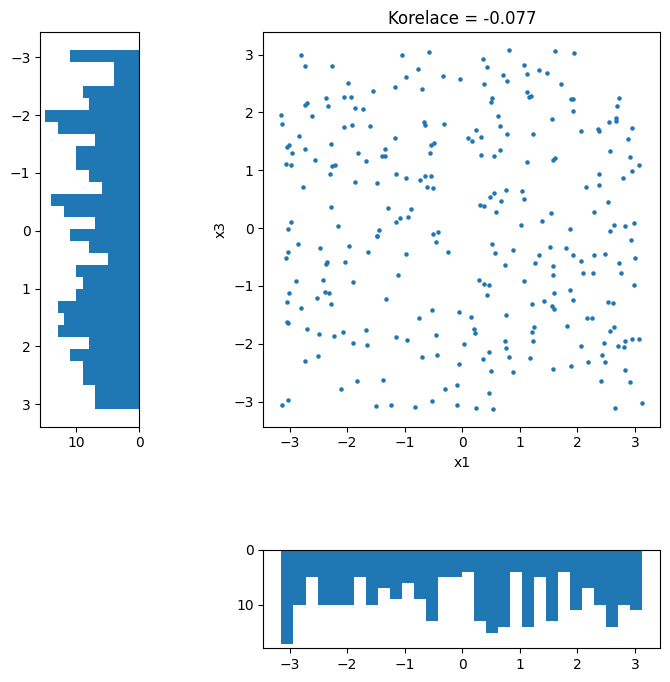

In [128]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(8,8))

gs = fig.add_gridspec(2, 2,width_ratios=(1,4), height_ratios=(4,1), hspace=0.5, wspace=0.5)

# osy
ax_histy = fig.add_subplot(gs[0,0])
ax_scatter = fig.add_subplot(gs[0,1])
ax_histx = fig.add_subplot(gs[1,1])

# data
x = xx_train[:,0]   # x1
y = xx_train[:,2]   # x3

# hlavní graf
ax_scatter.scatter(x, y, s=5)

# histogram x1 dole
ax_histx.hist(x, bins=30)
ax_histy.invert_yaxis()
ax_histx.invert_yaxis()

# histogram x2 vlevo
ax_histy.hist(y, bins=30, orientation='horizontal')
ax_histy.invert_xaxis()

# popisky
ax_scatter.set_xlabel('x1')
ax_scatter.set_ylabel('x3')

# spočítaní korelace
corr = np.corrcoef(x, y)[0,1]
ax_scatter.set_title(f'Korelace = {corr:.3f}')

plt.show()

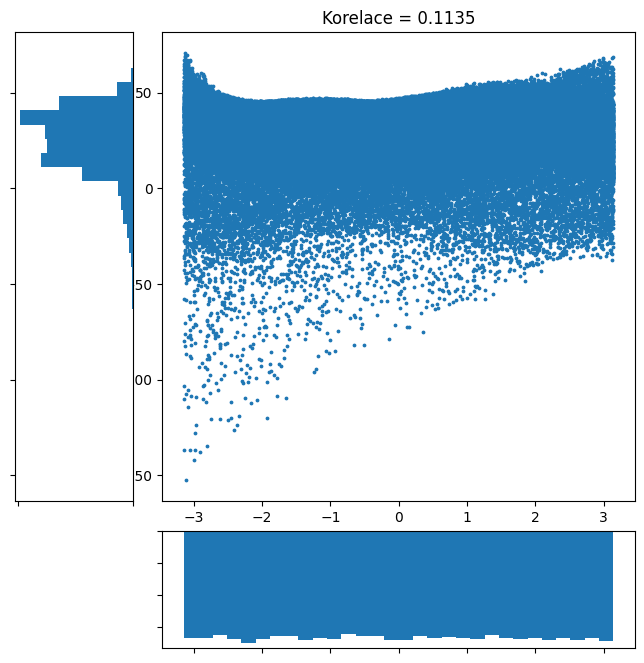

In [129]:
x = xx_val[:,0]
y = pce_metamodel.predict(xx_val).flatten()

corr = np.corrcoef(x, y)[0,1]

fig = plt.figure(figsize=(8,8))

gs = fig.add_gridspec(
    2, 2,
    width_ratios=(1,4),
    height_ratios=(4,1),
    hspace=0.1,
    wspace=0.1)

ax_scatter = fig.add_subplot(gs[0,1])
ax_histy = fig.add_subplot(gs[0,0], sharey=ax_scatter)
ax_histx = fig.add_subplot(gs[1,1], sharex=ax_scatter)

# scatter
ax_scatter.scatter(x, y, s=3)
ax_scatter.set_xlabel('x1')
ax_scatter.set_ylabel('PCE output')
ax_scatter.set_title(f'Korelace = {corr:.4f}')

# histogram y
ax_histy.hist(y, bins=30, orientation='horizontal')
ax_histy.invert_xaxis()

# histogram x
ax_histx.hist(x, bins=30)
ax_histx.invert_yaxis()

plt.setp(ax_histy.get_yticklabels(), visible=False)
plt.setp(ax_histx.get_xticklabels(), visible=False)

ax_histy.tick_params(axis='x', labelbottom=False)
ax_histx.tick_params(axis='y', labelleft=False)

plt.show()

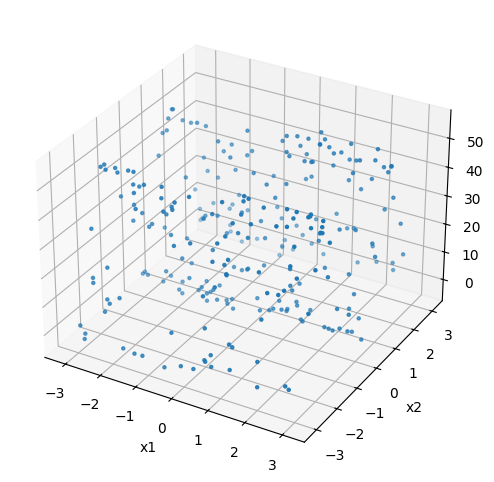

In [130]:
fig = plt.figure(figsize=(10,6))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(xx_train[:,0], xx_train[:,1],yy_train, s=5)
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_zlabel('x2')


plt.show()

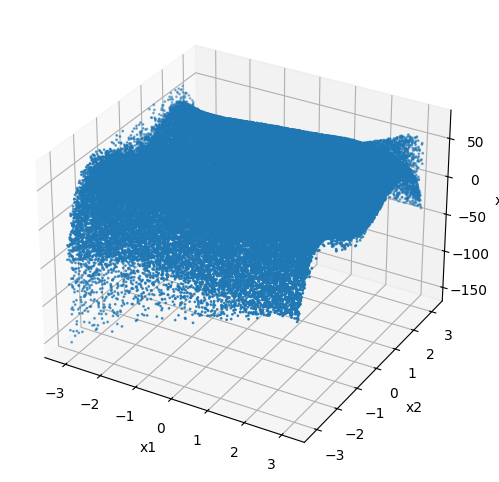

In [131]:
fig = plt.figure(figsize=(10,6))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(xx_val[:,0], xx_val[:,1],yy_val_pce, s=1)
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_zlabel('x2')


plt.show()

In [27]:
print(pce.coefficients.shape)
print(polynomial_basis.multi_index_set[:10])
print(pce.coefficients[:10])

(20, 1)
[[0 0 0]
 [1 0 0]
 [0 1 0]
 [0 0 1]
 [0 0 2]
 [0 1 1]
 [0 2 0]
 [1 1 0]
 [1 0 1]
 [2 0 0]]
[[24.30415173]
 [ 0.36913636]
 [ 0.43267619]
 [ 2.24444689]
 [-0.32045323]
 [ 2.80667879]
 [-3.6476394 ]
 [-0.69486406]
 [-1.98353494]
 [ 3.86841933]]


In [18]:
coeffs = pce_metamodel.coefficients.flatten()
indices = polynomial_basis.multi_index_set

for c, idx in zip(coeffs, indices):
    print(c, idx)

25.000001538123378 [0 0 0]
1.6254207490762642 [1 0 0]
-6.02432150276222e-06 [0 1 0]
4.667258585833167e-06 [0 0 1]
-3.9526076731633e-06 [0 0 2]
1.713879387854611e-06 [0 1 1]
-4.248017157860791 [0 2 0]
2.2499693028560364e-06 [1 1 0]
-8.855257656897875e-06 [1 0 1]
2.3208175337074977e-06 [2 0 0]
5.517673159899372e-06 [0 0 3]
-1.124766653001763e-05 [0 1 2]
1.06351704642349e-05 [0 2 1]
-4.2841538649973643e-07 [0 3 0]
1.372425849347905 [1 0 2]
7.753665531295972e-07 [1 1 1]
6.2351299298241125e-06 [1 2 0]
-3.948586103467988e-06 [2 1 0]
2.638520033793057e-06 [2 0 1]
-1.290633044082947 [3 0 0]
-3.5024335963140807e-06 [0 0 4]
7.001544353721356e-06 [0 1 3]
-8.41604038388788e-06 [0 2 2]
2.5878380330579542e-06 [0 3 1]
-13.94492729014367 [0 4 0]
-1.0449476119583911e-05 [1 0 3]
2.559098176979635e-06 [1 1 2]
-7.924072451565012e-06 [1 2 1]
6.022305794051164e-06 [1 3 0]
2.354675414123486e-06 [2 0 2]
8.093764547995042e-06 [2 1 1]
6.7768162175310676e-06 [2 2 0]
-3.900634971520933e-06 [3 1 0]
-8.504716301427